# Fig. 2: BarFly resolves the Luria-Delbruck distribution over four orders of magnitude

Expt 1, canavanine selection of a barcoded BY4741 msh2D library.

  2c  reads per barcode before and after selection.  Before selection the
      distribution is sharply peaked; after it spans four decades, and the inset
      shows the density on logarithmic axes against a slope -2 reference, the decay
      expected of the Luria-Delbruck distribution.

  2d  the mutant-number CCDF at a range of population sizes N, obtained by combining
      barcodes into virtual lineages.  Left is simulated, right is measured with the
      fitted Luria-Delbruck distribution overlaid; the dashed line is a slope -1
      reference, the cumulative of the -2 density.  Insets show the same comparison in
      Laplace space, where the theory is the closed form of SI Eq. 8.

mu and alpha are taken from the fit cached by `20260907_figS04_expt1_fit.py`, which
must be run first.  Runtime: ~1 min.

In [1]:
import sys
import time
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

ROOT = Path.cwd()
while not (ROOT / "barfly").is_dir():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

In [2]:
from barfly import expt1, ld                                          # noqa: E402
from barfly.plotting import colorTable, bin_count_colour, use_paper_style    # noqa: E402

OUT = ROOT / "output"; OUT.mkdir(exist_ok=True)
CACHE = ROOT / "cache"
use_paper_style()

SEED = 20260907
np.random.seed(SEED)
t_start = time.time()

fit = np.load(CACHE / "expt1_fit.npz")
KVEC = fit["kvec"]; n_bin_counts = len(KVEC)
# Read mu and alpha from the cached fit rather than restating them, so the overlay
# cannot drift away from the parameters it is meant to display.
MU = fit["mu_ls"][-1]
ALPHA = fit["alpha_ls"][-1]
MU_LAP = fit["mu_lap"][-1]
ALPHA_LAP = fit["alpha_lap"][-1]
print(f"using global LS fit mu = {MU:.3e}, alpha = {ALPHA:.3f}")
print(f"      global Laplace mu = {MU_LAP:.3e}, alpha = {ALPHA_LAP:.3f}")

bcds, counts_pre, counts_post, reads_post = expt1.load()
print(f"{len(bcds)} barcodes in the experiment.")

using global LS fit mu = 2.046e-06, alpha = 4.292
      global Laplace mu = 2.154e-06, alpha = 4.535
119672 barcodes in the experiment.


In [3]:
# Numbers quoted in the Results text
cells_per_bcd = expt1.TOTAL_CELLS * counts_pre / np.sum(counts_pre)
n_zero = int(np.sum(counts_post == 0))
print(f"median cells/barcode at t0: {np.median(cells_per_bcd):.3g} "
      f"(15th-85th pct {np.percentile(cells_per_bcd,15):.3g}-{np.percentile(cells_per_bcd,85):.3g})")
print(f"barcodes with zero counts after selection: {n_zero} "
      f"({100*n_zero/len(counts_post):.2f}%)")
print(f"reads in top 100 barcodes: "
      f"{100*np.sum(np.sort(counts_post)[-100:])/np.sum(counts_post):.2f}%")

median cells/barcode at t0: 4.9e+04 (15th-85th pct 1.19e+04-1.59e+05)
barcodes with zero counts after selection: 100028 (83.59%)
reads in top 100 barcodes: 44.92%


## 2c

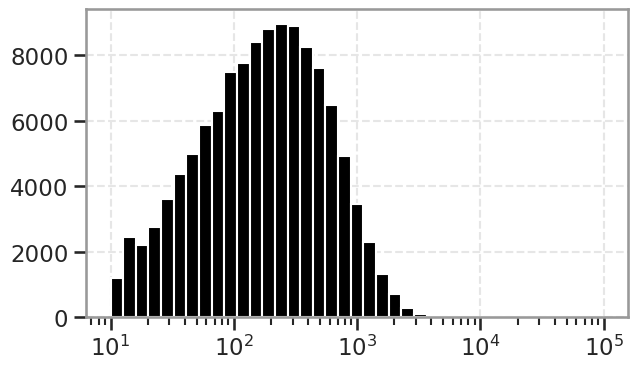

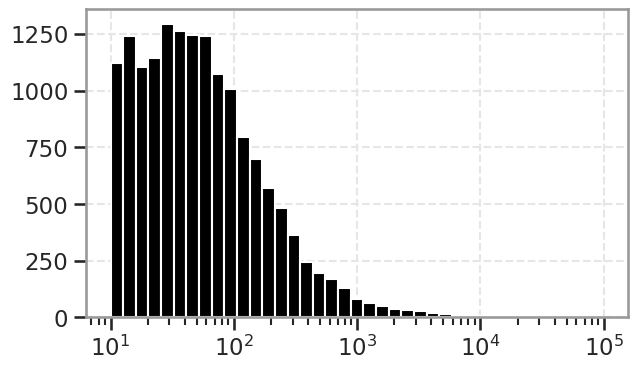

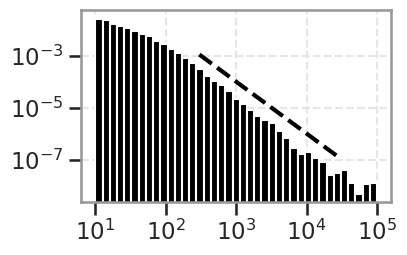

In [4]:
for name, dat in (("fig02c_countsAtT0.svg", counts_pre),
                  ("fig02c_countsAtTf.svg", counts_post)):
    fig = plt.figure(); fig.set_size_inches(7, 4)
    plt.hist(dat, bins=np.logspace(1, 5, 40), color="k")
    plt.xscale("log")
    plt.savefig(OUT / name, dpi=300); plt.show()

fig = plt.figure(); fig.set_size_inches(4, 2.5)
plt.hist(counts_post, bins=np.logspace(1, 5, 40), density=True, color="k")
plt.xscale("log"); plt.yscale("log")
xv = np.array([3e2, 3e4])
plt.plot(xv, 1e2 / xv**2, "--", color="k", linewidth=3)   # slope -2 reference
plt.xticks([1e1, 1e2, 1e3, 1e4, 1e5],
           ["$10^1$", "$10^2$", "$10^3$", "$10^4$", "$10^5$"])
plt.savefig(OUT / "fig02c_countsAtTf_density.svg", dpi=300); plt.show()

## binning and simulation for 2d

In [5]:
binned_post = {}
for i_k, n_bins in enumerate(KVEC):
    _, _, binned = ld.bin_barcodes(counts_pre, counts_post, n_bins)
    binned_post[i_k] = binned

t = time.time()
simulated = {i_k: ld.simulate_ld(MU, 1, n_replicates=5_000_000,
                                 population_size=expt1.TOTAL_CELLS / n_bins)
             for i_k, n_bins in enumerate(KVEC)}
print(f"theory curves simulated ({time.time()-t:.1f}s)")

# Reads to absolute mutant numbers, SI Eq. 10.  A lineage's share of the final-time
# reads, scaled to the plated mutant count M_cfu, times the calibration factor alpha.
# reads_post spans every barcode passing the lower cutoff, so the ratio is taken
# against the same population M_cfu was sampled from.
total_mutants = ALPHA * (np.sum(counts_post) / reads_post) * expt1.PLATED_CFU
XLIM = (1, 1e4)
# Fixed y-range so the left (theory) and right (experiment) panels of 2d share
# an axis and can be read against each other directly.
YLIM = (1.4717600466311862e-05, 1.6986464646342474)
xvtheory = np.logspace(0, 3.8, 200)
# Both 2d panels draw the same theory curves, so evaluate them once.
theory_ccdf = {i_k: ld.ccdf(simulated[i_k], xvtheory) for i_k in range(n_bin_counts)}

theory curves simulated (4.6s)


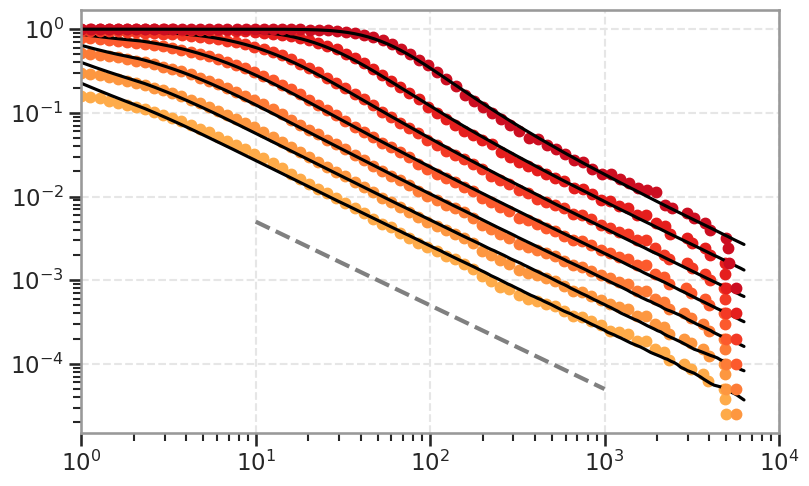

In [6]:
# 2d right: data + theory overlay
fig = plt.figure(); fig.set_size_inches(9, 5.5)
for i_k, n_bins in enumerate(KVEC):
    mutnumbers = total_mutants * binned_post[i_k] / np.sum(binned_post[i_k])
    desc = np.sort(mutnumbers)[::-1]
    # log-spaced up to the 11th largest, then the ten jackpots individually
    xv = np.concatenate([np.logspace(np.log10(0.3), np.log10(desc[10]), 75),
                         np.sort(desc[:10])])
    plt.plot(xv, ld.ccdf(mutnumbers, xv), ".", markersize=15,
             color=bin_count_colour(i_k, n_bin_counts), rasterized=True)
    plt.plot(xvtheory, theory_ccdf[i_k], "-k")
plt.plot([1e1, 1e3], 5e-2 / np.array([1e1, 1e3]), "--", color="gray", linewidth=3)
plt.xscale("log"); plt.yscale("log"); plt.xlim(*XLIM); plt.ylim(*YLIM)
plt.savefig(OUT / "fig02d_experiment.svg", dpi=300); plt.show()

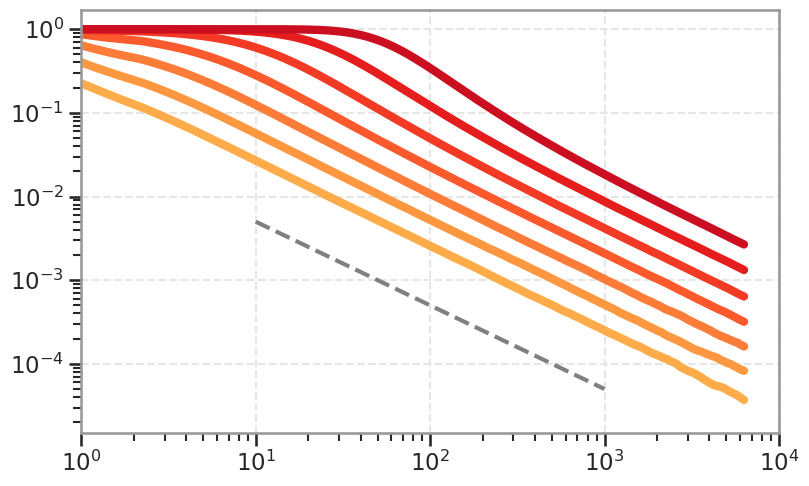

In [7]:
# 2d left: theory only
fig = plt.figure(); fig.set_size_inches(9, 5.5)
for i_k, n_bins in enumerate(KVEC):
    plt.plot(xvtheory, theory_ccdf[i_k], "-", linewidth=6,
             color=bin_count_colour(i_k, n_bin_counts), rasterized=True)
plt.plot([1e1, 1e3], 5e-2 / np.array([1e1, 1e3]), "--", color="gray", linewidth=3)
plt.xscale("log"); plt.yscale("log"); plt.xlim(*XLIM); plt.ylim(*YLIM)
plt.savefig(OUT / "fig02d_theoryCurves.svg", dpi=300); plt.show()

## 2d insets: Laplace transform

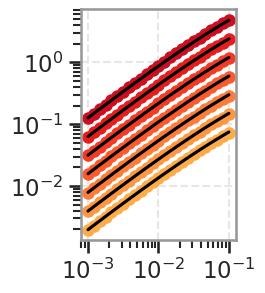

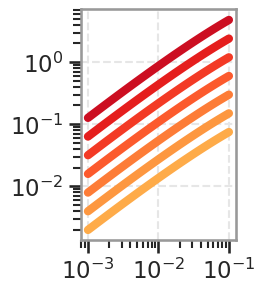

Done in 9.8s.


In [8]:
svec = np.logspace(-3, -1, 30)
plotsvec = np.logspace(-3, -1, 25)
baretheory = ld.unit_laplace_transform(svec)
# the same calibration at alpha = 1, so the Laplace fit can apply its own alpha
mutants_at_alpha1 = {
    i_k: (np.sum(counts_post) / reads_post) * expt1.PLATED_CFU
         * binned_post[i_k] / np.sum(binned_post[i_k])
    for i_k in range(n_bin_counts)}

fig = plt.figure(); fig.set_size_inches(2, 3)
for i_k, n_bins in enumerate(KVEC):
    lnP_data = ld.empirical_laplace_transform(
        ALPHA_LAP * mutants_at_alpha1[i_k], plotsvec)
    lnP_theory = MU_LAP * (expt1.TOTAL_CELLS / n_bins) * baretheory
    plt.plot(plotsvec, -lnP_data, "o", color=bin_count_colour(i_k, n_bin_counts), markersize=8)
    plt.plot(svec, -lnP_theory, "-k")
plt.yscale("log"); plt.xscale("log")
plt.savefig(OUT / "fig02d_laplaceFit.svg", dpi=300); plt.show()

fig = plt.figure(); fig.set_size_inches(2, 3)
for i_k, n_bins in enumerate(KVEC):
    plt.plot(svec, -(MU_LAP * (expt1.TOTAL_CELLS / n_bins) * baretheory), "-",
             color=bin_count_colour(i_k, n_bin_counts), linewidth=6)
plt.yscale("log"); plt.xscale("log")
plt.savefig(OUT / "fig02d_laplaceTheory.svg", dpi=300); plt.show()

print(f"Done in {time.time()-t_start:.1f}s.")